# WIA3002: Academic Project I
## A Quantum Convolutional Neural Network (QCNN) Framework for Automated Sex Estimation Using Orbital and Nasal Craniofacial Measurements

**Name:**  Wong Jing Wen  
**Matric Number:**  23004924

##1.0 Install Required Package

In [ ]:
!pip install xlrd openpyxl -q

##2.0 Dataset Preparation

###2.1 Upload Dataset

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Orbital, Nasal and Craniofacial Class Pattern.xls to Orbital, Nasal and Craniofacial Class Pattern (1).xls


###2.2 Load Dataset

In [ ]:
import pandas as pd
import numpy as np

file_name = list(uploaded.keys())[0]

df = pd.read_excel(file_name, sheet_name="Raw Data")
df = df.drop(columns=["Autopsy Num"])

df.head()

,No.,Age Group,Age,Gender,Ethnicity,Ec-Dc\nOrbital Width,REc-RDc\nRight Orbital Width,LEc-LDc\nLeft Orbital Width,UMo-Lmo\nOrbital Height,RUMo-RLMo\nRight Orbital Height,LUMo-LLMo\nLeft Orbital Height,RAI-LAI\nNasal Width,Rh-Ns\nNasal Height,S-N-B\nAngle,S-N-A\nAngle,A-N-B Angle\nS-N-A - S-N-B,CRANIOFACIAL CLASS,CRANIOFACIAL CLASS.1,Count,Unnamed: 20
0,1,2,24,M,MALAY,43.444446,43.568351,43.320540,38.188085,39.471382,36.904789,25.156459,30.313593,79.751054,86.135809,6.384755,Class II,Class I,354.0,Class I (normal skeletal relationship): ANB be...
1,2,2,21,M,MALAY,41.661525,41.347988,41.975061,35.200922,35.278933,35.122911,25.627671,30.816723,79.040981,79.695832,0.654851,Class I,Class II,536.0,Class II (mandibular retrusion or maxillary pr...
2,3,2,29,M,MALAY,39.775020,40.220856,39.329184,35.284720,34.987107,35.582332,27.177079,30.331595,84.634076,87.527812,2.893736,Class I,Class III,152.0,Class III (mandibular protrusion or maxillary ...
3,4,2,27,M,MALAY,45.082304,44.746330,45.418279,36.759280,37.372576,36.145984,26.329185,35.501703,78.896739,75.607622,-3.289117,Class III,NaN,NaN,NaN
4,5,2,25,M,MALAY,41.821028,42.107087,41.534970,35.190416,34.821953,35.558880,26.640460,30.439414,81.996817,85.111067,3.114250,Class I,NaN,NaN,NaN


###2.3 Dataset Checking

In [ ]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (1042, 20)

Columns:
Index(['No.', ' Age Group', ' Age', ' Gender', ' Ethnicity',
       'Ec-Dc\nOrbital Width', 'REc-RDc\nRight Orbital Width',
       'LEc-LDc\nLeft Orbital Width', 'UMo-Lmo\nOrbital Height',
       'RUMo-RLMo\nRight Orbital Height', 'LUMo-LLMo\nLeft Orbital Height',
       'RAI-LAI\nNasal Width', 'Rh-Ns\nNasal Height', 'S-N-B\nAngle',
       'S-N-A\nAngle', 'A-N-B Angle\nS-N-A - S-N-B', 'CRANIOFACIAL CLASS',
       'CRANIOFACIAL CLASS.1', 'Count', 'Unnamed: 20'],
      dtype='object')

Missing values:
No.                                   0
 Age Group                            0
 Age                                  0
 Gender                               0
 Ethnicity                            0
Ec-Dc\nOrbital Width                  0
REc-RDc\nRight Orbital Width          0
LEc-LDc\nLeft Orbital Width           0
UMo-Lmo\nOrbital Height               0
RUMo-RLMo\nRight Orbital Height       0
LUMo-LLMo\nLeft Orbital Height        0
RAI-LAI\nNasal Widt

###3.0 Data Pre-processing

###3.1 Clean Column Names

In [ ]:
df.columns = (
    df.columns
    .astype(str)
    .str.strip()
    .str.replace("\n", " ", regex=False)
    .str.replace("  ", " ", regex=False)
)

df.head()

,No.,Age Group,Age,Gender,Ethnicity,Ec-Dc Orbital Width,REc-RDc Right Orbital Width,LEc-LDc Left Orbital Width,UMo-Lmo Orbital Height,RUMo-RLMo Right Orbital Height,LUMo-LLMo Left Orbital Height,RAI-LAI Nasal Width,Rh-Ns Nasal Height,S-N-B Angle,S-N-A Angle,A-N-B Angle S-N-A - S-N-B,CRANIOFACIAL CLASS,CRANIOFACIAL CLASS.1,Count,Unnamed: 20
0,1,2,24,M,MALAY,43.444446,43.568351,43.320540,38.188085,39.471382,36.904789,25.156459,30.313593,79.751054,86.135809,6.384755,Class II,Class I,354.0,Class I (normal skeletal relationship): ANB be...
1,2,2,21,M,MALAY,41.661525,41.347988,41.975061,35.200922,35.278933,35.122911,25.627671,30.816723,79.040981,79.695832,0.654851,Class I,Class II,536.0,Class II (mandibular retrusion or maxillary pr...
2,3,2,29,M,MALAY,39.775020,40.220856,39.329184,35.284720,34.987107,35.582332,27.177079,30.331595,84.634076,87.527812,2.893736,Class I,Class III,152.0,Class III (mandibular protrusion or maxillary ...
3,4,2,27,M,MALAY,45.082304,44.746330,45.418279,36.759280,37.372576,36.145984,26.329185,35.501703,78.896739,75.607622,-3.289117,Class III,NaN,NaN,NaN
4,5,2,25,M,MALAY,41.821028,42.107087,41.534970,35.190416,34.821953,35.558880,26.640460,30.439414,81.996817,85.111067,3.114250,Class I,NaN,NaN,NaN


###3.2 Clean Text Value

In [ ]:
# Remove extra spaces from all text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip()

# Check again
print("Gender classes after cleaning:")
print(df["Gender"].unique())

print("\nEthnicity classes after cleaning:")
print(df["Ethnicity"].unique())

Gender classes after cleaning:
['M' 'F']

Ethnicity classes after cleaning:
['MALAY' 'CHINESE' 'INDIAN']


###3.3 Dataset Distribution

In [ ]:
print("Gender Distribution:")
print(df["Gender"].value_counts())

print("\nEthnicity Distribution:")
print(df["Ethnicity"].value_counts())

print("\nCraniofacial Class Distribution:")
print(df["CRANIOFACIAL CLASS"].value_counts())

Gender Distribution:
Gender
M    587
F    455
Name: count, dtype: int64

Ethnicity Distribution:
Ethnicity
MALAY      380
CHINESE    380
INDIAN     282
Name: count, dtype: int64

Craniofacial Class Distribution:
CRANIOFACIAL CLASS
Class II     536
Class I      354
Class III    152
Name: count, dtype: int64


###3.4 Feature Selection

In [ ]:
feature_cols = [
    "Ec-Dc Orbital Width",
    "REc-RDc Right Orbital Width",
    "LEc-LDc Left Orbital Width",
    "UMo-Lmo Orbital Height",
    "RUMo-RLMo Right Orbital Height",
    "LUMo-LLMo Left Orbital Height",
    "RAI-LAI Nasal Width",
    "Rh-Ns Nasal Height"
]

target_col = "Gender"

X = df[feature_cols]
y = df[target_col]

X.head()

,Ec-Dc Orbital Width,REc-RDc Right Orbital Width,LEc-LDc Left Orbital Width,UMo-Lmo Orbital Height,RUMo-RLMo Right Orbital Height,LUMo-LLMo Left Orbital Height,RAI-LAI Nasal Width,Rh-Ns Nasal Height
0,43.444446,43.568351,43.320540,38.188085,39.471382,36.904789,25.156459,30.313593
1,41.661525,41.347988,41.975061,35.200922,35.278933,35.122911,25.627671,30.816723
2,39.775020,40.220856,39.329184,35.284720,34.987107,35.582332,27.177079,30.331595
3,45.082304,44.746330,45.418279,36.759280,37.372576,36.145984,26.329185,35.501703
4,41.821028,42.107087,41.534970,35.190416,34.821953,35.558880,26.640460,30.439414


###3.5 Label Encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("Encoded example:", y_encoded[:10])

Classes: ['F' 'M']
Encoded example: [1 1 1 1 1 1 1 1 1 1]


###3.6 Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (833, 8)
Testing data: (209, 8)


###3.7 Exploratory Orbital and Nasal Morphometric Analysis

,Ec-Dc Orbital Width,REc-RDc Right Orbital Width,LEc-LDc Left Orbital Width,UMo-Lmo Orbital Height,RUMo-RLMo Right Orbital Height,LUMo-LLMo Left Orbital Height,RAI-LAI Nasal Width,Rh-Ns Nasal Height
Gender,,,,,,,,
F,40.734709,41.071841,40.397577,35.052319,35.071087,35.033551,25.314404,29.229265
M,42.039380,42.351690,41.727069,35.885129,36.073770,35.696487,26.249739,32.122878


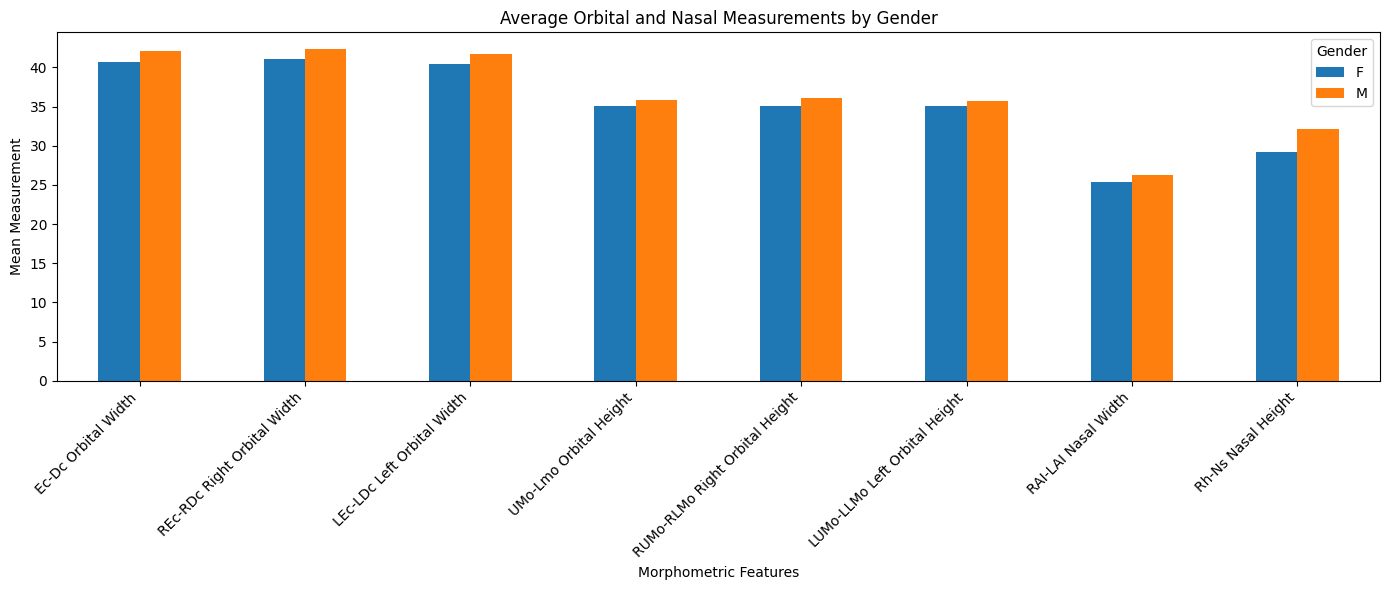

,Ec-Dc Orbital Width,REc-RDc Right Orbital Width,LEc-LDc Left Orbital Width,UMo-Lmo Orbital Height,RUMo-RLMo Right Orbital Height,LUMo-LLMo Left Orbital Height,RAI-LAI Nasal Width,Rh-Ns Nasal Height
Age Group,,,,,,,,
2,41.678985,42.034603,41.323367,35.423610,35.565790,35.281430,24.932798,30.656864
3,41.798220,42.125662,41.470779,35.412352,35.522908,35.301795,25.553153,30.977506
4,41.541896,41.883068,41.200724,35.548611,35.641064,35.456157,25.546649,30.837153
5,41.256943,41.578115,40.935772,35.325249,35.495082,35.155416,26.067647,30.848812
6,41.227852,41.504359,40.951346,35.719123,35.809740,35.628507,25.983056,30.864288
7,41.276475,41.591041,40.961908,35.786747,35.853217,35.720277,27.333399,30.997292


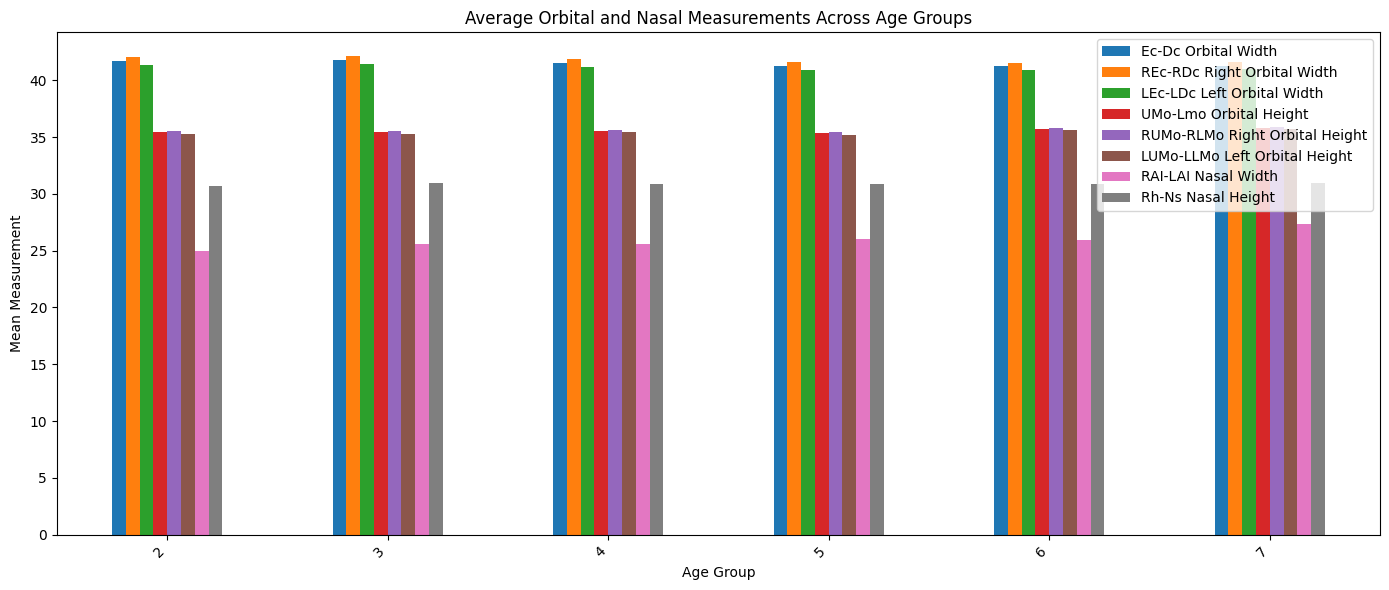

In [ ]:

import matplotlib.pyplot as plt

# Average orbital/nasal measurements by gender
gender_summary = df.groupby("Gender")[feature_cols].mean()
display(gender_summary)

gender_summary.T.plot(kind="bar", figsize=(14, 6))
plt.title("Average Orbital and Nasal Measurements by Gender")
plt.xlabel("Morphometric Features")
plt.ylabel("Mean Measurement")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Average orbital/nasal measurements by age group
age_summary = df.groupby("Age Group")[feature_cols].mean()
display(age_summary)

age_summary.plot(kind="bar", figsize=(14, 6))
plt.title("Average Orbital and Nasal Measurements Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Mean Measurement")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

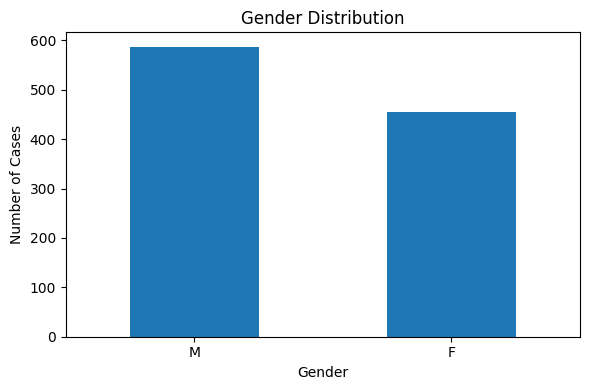

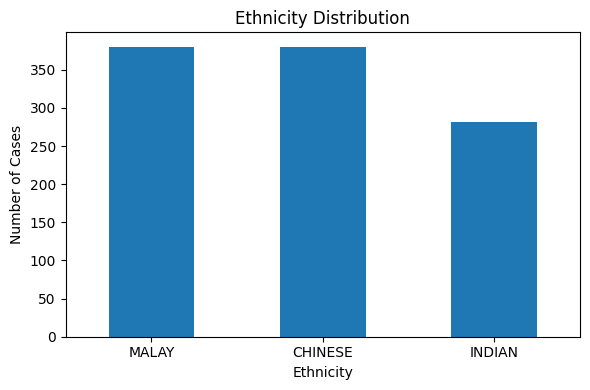

In [ ]:
# =========================
# Dataset Distribution Charts
# =========================
import matplotlib.pyplot as plt

# Gender Distribution
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(6, 4))
gender_counts.plot(kind="bar")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Cases")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Ethnicity Distribution
ethnicity_counts = df["Ethnicity"].value_counts()

plt.figure(figsize=(6, 4))
ethnicity_counts.plot(kind="bar")
plt.title("Ethnicity Distribution")
plt.xlabel("Ethnicity")
plt.ylabel("Number of Cases")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##4.0 Classical Baseline MLP Model

###4.1 Normalization & Baseline Model

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

mlp_model = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        max_iter=1000,
        random_state=42
    ))
])

mlp_model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Pipeline(steps=[('scaler', StandardScaler()),
                ('mlp',
                 MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000,
                               random_state=42))])

###4.2 Model Evaluation

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict test data
y_pred = mlp_model.predict(X_test)

# Store metrics into variables
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="binary")
recall = recall_score(y_test, y_pred, average="binary")
f1 = f1_score(y_test, y_pred, average="binary")

# Print metrics
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.6794258373205742
Precision: 0.717948717948718
Recall: 0.711864406779661
F1-score: 0.7148936170212766

Classification Report:
              precision    recall  f1-score   support

           F       0.63      0.64      0.63        91
           M       0.72      0.71      0.71       118

    accuracy                           0.68       209
   macro avg       0.67      0.67      0.67       209
weighted avg       0.68      0.68      0.68       209


Confusion Matrix:
[[58 33]
 [34 84]]
